# 01 · Preprocessing — Karaayvas 2018 Breast Cancer (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven count gap**, integrate
patients (Harmony), embed, remove detached islands, and check the manifold's sub-structure.
Karaayvas 2018 is **SmartSeq2** (deep, full-length; 6 TNBC patients), so per-sample cell counts
are small and the head-and-neck anchor's `≥100` floor is not portable — the threshold is derived
from *this* dataset's count distribution. Every tunable choice is derived here, not inherited.
Deliverable: `processed.h5ad`, `samples.pdf`.

In [ ]:
import os, sys, glob, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Karaayvas2018_Breast-1
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Breast
name_in = re.sub(r'-\d+$', '', name)                    # strip run suffix -> raw input folder
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name_in)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw input:', 'Data_' + name_in)

dataset: Karaayvas2018_Breast-1 | category: Breast | raw input: Data_Karaayvas2018_Breast


### Load malignant compartment
Karaayvas et al. annotate cell types directly; we take their `Malignant` calls. Expression is
**TPM** (SmartSeq2), passed through by the loader and `log1p`-transformed.

In [ ]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p TPM)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Karaayvas2018_Breast
Done.
full atlas: (1534, 21785)
malignant: (365, 21785) | samples: 6
expression: X max 12.24 (log1p TPM)


### Sample thresholding — derived from the per-sample count gap
The anchor floor of 100 (Puram HNSCC) exceeds every Karaayvas sample except one, so it is not
portable to a small-n SmartSeq2 dataset (the Chung 2017 SmartSeq2-Breast precedent). We instead
read the largest **multiplicative gap** in the sorted per-sample malignant counts: a clean cliff
separates the tumour-bearing samples from a spillover sample, and we cut above it. A floor of ~10
is the scale-appropriate minimum for a stable per-sample Harmony centroid.

In [ ]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
print('sorted per-sample malignant counts:', dict(zip(n.index.tolist(), n.values.astype(int).tolist())))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'anchor floor 100 would keep only {int((vals>=100).sum())}/{len(vals)} samples -> not portable')
FLOOR = 10   # scale-appropriate minimum cells for a stable per-sample batch centroid
keep = n.index[n >= FLOOR]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'FLOOR = {FLOOR} -> kept {len(keep)}/{len(n)} samples (dropped {list(n.index[n < FLOOR])}); '
      f'{adata.shape[0]} cells; min per-sample = {int(n[n>=FLOOR].min())}')

sorted per-sample malignant counts: {'39': 128, '89': 89, '81': 68, '84': 44, '126': 31, '58': 5}
gap ratios: ['128->89:1.44', '89->68:1.31', '68->44:1.55', '44->31:1.42', '31->5:6.20']
largest multiplicative gap: 31 -> 5 (ratio 6.20)
anchor floor 100 would keep only 1/6 samples -> not portable
FLOOR = 10 -> kept 5/6 samples (dropped ['58']); 360 cells; min per-sample = 31


### Overdispersion, PCA, Harmony integration, embedding
Overdispersed genes via scFates' GAM fit; PCA; Harmony on `sample`. `theta` is selected by a
same-sample-neighbour-fraction sweep (lower = better mixing) — we take the strongest integration
past which mixing stops improving. PC count (20) and UMAP spread (1.3) follow the comparable
small-n SmartSeq2 precedent (Chung 2017).

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PCA variance ratio[:12]:', np.round(vr[:12], 4).tolist())

from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('random baseline ~ %.3f' % (1.0/adata.obs['sample'].nunique()))
print('same-sample neighbour fraction | pre-Harmony %.3f' % base, '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing improves sharply to theta=5 then flattens; theta=10 within',
      'noise of theta=5 -- strongest integration of the SmartSeq2 patient batch effect without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 51 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 51
PCA variance ratio[:12]: [0.2014, 0.1144, 0.0753, 0.0548, 0.045, 0.0329, 0.027, 0.0257, 0.0209, 0.0209, 0.0183, 0.0172]
2026-08-05 17:59:34,599 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 17:59:34,637 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 17:59:34,638 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 17:59:34,676 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 17:59:34,700 - harmonypy - INFO - Converged after 2 iterations
2026-08-05 17:59:34,712 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 17:59:34,750 - 

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance), keep only the largest
connected component — strips physically detached specks while retaining the continuous body.

In [ ]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
if int((lab!=main).sum()) > 0:
    sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)

removed 0 cells in 0 detached islands


### Sub-structure: cycling & signature check (biology before the Gate-1 GO)
Low-resolution Leiden recovers the manifold's lobes; we ask whether any split is a developmental
or a proliferation partition that would require scoping the trajectory (the Kürten 2021 lobe-identity
fork). We score the three embryonic modules against the shared **union** control pool and the cell-cycle
phase, then compare lobes.

In [ ]:
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
print('lobe smoothed module means:')
print(adata.obs.groupby('lobe', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(3).to_string())
print('-> lobes carry near-identical developmental means and both are low-cycling: the split is neither',
      'a developmental nor a proliferation partition. Keep the whole manifold as one trajectory object',
      '(the Bischoff/Sun/Chung single-body case, not the Kurten lobe-scoping case).')
adata.obs['compartment'] = pd.Categorical(['Body']*adata.n_obs)

Gast: 72/81 genes present
pSom: 86/98 genes present
Crest: 101/104 genes present
raw module means: {'Gast': -0.22, 'pSom': 0.1058, 'Crest': -0.0665}
lobe sizes: {'0': 190, '1': 170}
overall cycling fraction: 0.136
cycling fraction per lobe: {'0': 0.179, '1': 0.088}
lobe smoothed module means:
      Gast_sm  pSom_sm  Crest_sm
lobe                            
0      -0.236    0.101    -0.063
1      -0.214    0.096    -0.049
-> lobes carry near-identical developmental means and both are low-cycling: the split is neither a developmental nor a proliferation partition. Keep the whole manifold as one trajectory object (the Bischoff/Sun/Chung single-body case, not the Kurten lobe-scoping case).


### Orient the embedding to house linear layout (developmental origin → left)
Rigid rotation of the raw UMAP so its principal axis is horizontal (a rotation, **not** a
re-embedding — no fold can be introduced), then a discrete sign flip so the **gastrulation-high**
developmental origin lands on the left (the origin score is Gast-dominated here; pSom is low and Crest elevated
at this root — the Gate-2 inversion). This `X_umap_lin` is used for every deliverable
panel; pseudotime direction is confirmed in 02.

In [ ]:
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot),-np.sin(-theta_rot)],[np.sin(-theta_rot),np.cos(-theta_rot)]])
xyr = c @ Rm.T
origin = (adata.obs['Gast_sm'] + adata.obs['pSom_sm'] - adata.obs['Crest_sm']).values
w = origin - origin.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg, gastrulation-high developmental origin on left -> X_umap_lin')

manifold aspect (max/min std): 1.37
house orientation: rigid rotation +72.0deg, gastrulation-high developmental origin on left -> X_umap_lin


### Gate 1 — batch mixing & manifold continuity (per-neighbourhood, on the embedding)
Judged on the regenerated embedding with a **per-neighbourhood** metric (iLISI over the k-NN of
each cell), not a single scalar. Integration is swept over n_pcs to confirm robustness.

In [ ]:
def _ilisi(rep, labels, k=60):
    k = min(k, len(rep)-1)
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/L.shape[1]; out[i] = 1.0/np.sum(p**2)
    return out
n_samp = adata.obs['sample'].nunique()
for npc in [15, 20, 30]:
    ilp = np.median(_ilisi(adata.obsm['X_pca'][:,:npc], adata.obs['sample'].values))
    ilh = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:npc], adata.obs['sample'].values))
    print(f'iLISI median n_pcs={npc}: pre {ilp:.2f} -> post-Harmony(theta={theta}) {ilh:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one connected component (0 detached islands removed).')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS (GO)')

iLISI median n_pcs=15: pre 1.47 -> post-Harmony(theta=10) 4.04 of 5 samples
iLISI median n_pcs=20: pre 1.48 -> post-Harmony(theta=10) 4.08 of 5 samples
iLISI median n_pcs=30: pre 1.51 -> post-Harmony(theta=10) 4.02 of 5 samples
5 samples share one connected component (0 detached islands removed).
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS (GO)


### Save processed data

In [ ]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','disease','patient'}
for col in list(adata.obs.columns):
    if col in protect:
        adata.obs[col] = adata.obs[col].astype(str).astype('category'); continue
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        keep_num = s.notna().sum() > 0 and conv.notna().sum() >= 0.9*s.notna().sum()
        adata.obs[col] = conv if keep_num else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (360, 16243)


### Sample-integration figure (deliverable `samples.pdf`)
House style: `figsize=(3.5,1.5)`, `size=30`, pseudotime-oriented `X_umap_lin`. Colour = sample;
intermixing across the manifold is the Gate-1 batch-integration evidence.

saved samples.pdf | cells: 360


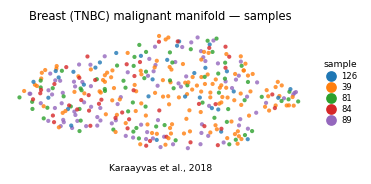

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Breast (TNBC) malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Karaayvas et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])